# MMP/PICS: source windows and positional count matrices

Recover the deposited P6–P6′ windows for nine MMPs from both peptide libraries. Inspect the available evidence and construct a selectable P4–P4′ count matrix without merging it into MEROPS.

## Introduction

Source: Eckhard et al., *Active site specificity profiling datasets of matrix metalloproteinases (MMPs) 1, 2, 3, 7, 8, 9, 12, 13 and 14*, 2016, [doi:10.1016/j.dib.2016.02.036](https://doi.org/10.1016/j.dib.2016.02.036), [PMC4777984](https://pmc.ncbi.nlm.nih.gov/articles/PMC4777984/), PRIDE PXD002265.

K562 proteome-derived peptide libraries were generated with trypsin or GluC. Cleavage creates neo-N termini, which are enriched and identified by mass spectrometry; WebPICS reconstructs the non-prime side from source sequences. These are observed/reconstructed cleavage windows, not kinetic constants. Library construction and detection affect the observed composition.

**Assumptions and notation.** Original windows have 12 positions P6–P6′; the central eight are P4–P4′ (`raw_window[2:10]`). A dash is an unresolved/unavailable residue and contributes no count. Original `PICS Output` and `PICS Output - unique` columns are retained as different representations; neither is silently combined with the other. A unique window string is not necessarily a unique genomic site.

Workbook roles: `mmc4` describes MMPs and structures; `mmc5` gives trypsin-library windows; `mmc6` gives GluC-library windows; `mmc7` contains cooperativity tables; `mmc8` contains quenched-fluorescent assay data; `mmc9` gives search settings; `mmc10.zip` contains WebPICS results. Only `mmc5` and `mmc6` feed the window counts here. The raw files are not changed and no exports are produced.

The defined-substrate dynamic assays are inspected in [0_04_mmp_pics_qf_measurements.ipynb](0_04_mmp_pics_qf_measurements.ipynb); their cut chemistry and motif-level source frequencies are compared in [0_05_mmp_pics_defined_sites.ipynb](0_05_mmp_pics_defined_sites.ipynb).

In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "src/pep_compass").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
RAW = ROOT / "data/proteolysis/window_neighbourhood_datasets/raw"
MEROPS = RAW / "merops"
pd.set_option("display.max_columns", None)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
import re
from pep_compass.steps.helpers.proteolysis import (
    MEROPS_AMINO_ACIDS, MEROPS_SUBSITES, specificity_counts_from_windows,
)

MMP_TO_MEROPS = {
    "MMP1": "M10.001", "MMP2": "M10.003", "MMP3": "M10.005", "MMP7": "M10.008",
    "MMP8": "M10.002", "MMP9": "M10.004", "MMP12": "M10.009", "MMP13": "M10.013", "MMP14": "M10.014",
}
REPRESENTATIONS = ("PICS Output", "PICS Output - unique")
records = []
# Read named source columns; retain the exact workbook, sheet and cell locator.
for filename, suffix, library in (("mmc5.xlsx", "_T", "trypsin"), ("mmc6.xlsx", "_G", "GluC")):
    with pd.ExcelFile(RAW / "mmp_pics" / filename) as workbook:
        for sheet in workbook.sheet_names:
            if not sheet.endswith(suffix):
                continue
            enzyme = sheet[:-len(suffix)]
            frame = pd.read_excel(workbook, sheet_name=sheet, header=None)
            for representation in REPRESENTATIONS:
                locations = np.argwhere(frame.eq(representation).to_numpy())  # (H, 2)
                # Headers also occur above numeric summary cells; select the window column.
                window_columns = []
                for header_row, column in locations:
                    candidate = frame.iloc[header_row + 1:, column].dropna()
                    if candidate.astype(str).str.fullmatch(r"[ACDEFGHIKLMNPQRSTVWY-]{12}").any():
                        window_columns.append((header_row, column))
                if len(window_columns) != 1:
                    raise ValueError(f"Expected one {representation!r} window column in {filename}/{sheet}")
                header_row, column = window_columns[0]
                values = frame.iloc[header_row + 1:, column].dropna()
                reported_counts = [frame.iat[int(row + 1), int(col)] for row, col in locations
                                   if isinstance(frame.iat[int(row + 1), int(col)], (int, float, np.number))]
                if len(reported_counts) != 1 or reported_counts[0] != len(values):
                    raise ValueError(f"Window count disagrees with source summary in {filename}/{sheet}")
                for row_index, value in values.items():
                    if not isinstance(value, str) or not re.fullmatch(r"[ACDEFGHIKLMNPQRSTVWY-]{12}", value):
                        raise ValueError(f"Unsupported window at {filename}/{sheet}/{row_index + 1}")
                    records.append({
                        "file": filename, "sheet": sheet, "excel_row": row_index + 1,
                        "excel_column": int(column + 1), "enzyme": enzyme,
                        "merops_code": MMP_TO_MEROPS[enzyme], "library": library,
                        "representation": representation, "raw_window": value, "window": value[2:10],
                    })
window_records = pd.DataFrame(records)
window_records["full_8_residues"] = ~window_records["window"].str.contains("-", regex=False)
source_summary = window_records.groupby(["enzyme", "merops_code", "library", "representation"]).agg(
    source_rows=("window", "size"), distinct_12_residue_windows=("raw_window", "nunique"),
    distinct_8_residue_windows=("window", "nunique"), full_8_residue_rows=("full_8_residues", "sum"),
).reset_index()
display(source_summary)
display(window_records[["file", "sheet", "excel_row", "representation", "raw_window", "window"]].head(3))

,enzyme,merops_code,library,representation,source_rows,distinct_12_residue_windows,distinct_8_residue_windows,full_8_residue_rows
0,MMP1,M10.001,GluC,PICS Output,126,116,114,99
1,MMP1,M10.001,GluC,PICS Output - unique,116,116,114,89
2,MMP1,M10.001,trypsin,PICS Output,277,270,269,227
3,MMP1,M10.001,trypsin,PICS Output - unique,270,270,269,222
4,MMP12,M10.009,GluC,PICS Output,124,107,107,93
5,MMP12,M10.009,GluC,PICS Output - unique,107,107,107,81
6,MMP12,M10.009,trypsin,PICS Output,275,259,259,213
7,MMP12,M10.009,trypsin,PICS Output - unique,259,259,259,200
8,MMP13,M10.013,GluC,PICS Output,130,124,124,99
9,MMP13,M10.013,GluC,PICS Output - unique,124,124,124,95


,file,sheet,excel_row,representation,raw_window,window
0,mmc5.xlsx,MMP1_T,4,PICS Output,SSVSMIASRKPT,VSMIASRK
1,mmc5.xlsx,MMP1_T,5,PICS Output,DMIVC-AYAHEL,IVC-AYAH
2,mmc5.xlsx,MMP1_T,6,PICS Output,YQEPIPCEQLVT,EPIPCEQL


## Select a matrix without pooling source strata

### Methodology

Each selected source row contributes one occurrence to each observed position. Select one MMP, one library and one original representation below. Display the integer `(8, 20)` occurrence matrix and its positional depth; no smoothing or rate weighting is applied. The heat map shows residue counts (colour), amino acids (x) and positions (y). Missing positions contribute zero; these zeros are not evidence of inhibition.

The old analysis used the first `PICS Output` column; the default below preserves that choice. Switching to the deposited `- unique` column is explicit and leaves both source representations available in `window_records`. The MEROPS code mapping is inherited from the old analysis and must be retained as a crosswalk when integrating.

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
P4,19,3,12,10,9,20,5,15,7,22,6,5,15,10,4,22,18,24,6,8
P3,32,12,6,9,5,9,5,16,0,22,2,6,74,2,0,16,10,35,2,2
P2,23,11,24,24,16,11,6,6,0,37,10,10,0,34,0,25,6,7,3,14
P1,50,6,18,12,14,25,8,3,0,10,5,31,24,16,0,33,8,2,1,4
P1p,2,6,2,2,5,0,3,54,0,138,23,2,1,8,0,1,5,22,0,3
P2p,25,2,3,5,10,5,13,30,7,44,14,11,0,15,3,14,18,49,1,8
P3p,69,0,31,24,5,32,9,6,0,4,1,9,5,15,1,23,17,22,2,2
P4p,44,2,16,27,9,28,10,6,6,24,6,14,14,6,5,12,15,26,1,6


,position,observed_residues
0,P4,240
1,P3,265
2,P2,267
3,P1,270
4,P1p,277
5,P2p,277
6,P3p,277
7,P4p,277


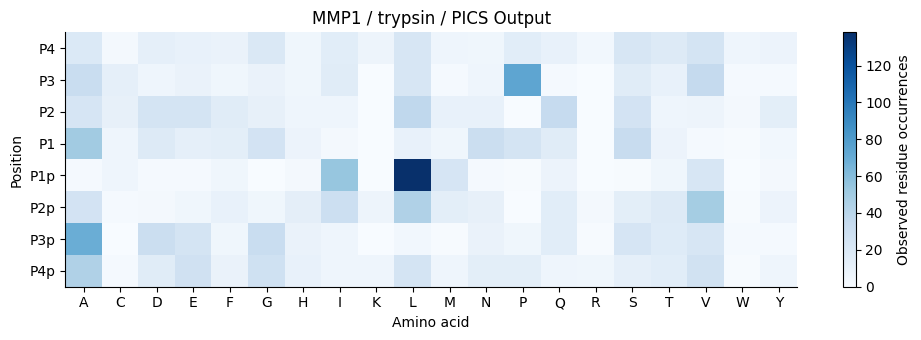

In [3]:
# Change these source selections to inspect another matrix.
ENZYME = "MMP1"
LIBRARY = "trypsin"
REPRESENTATION = "PICS Output"
FIGURE_SIZE = (10, 3.5)

selected_windows = window_records.loc[
    window_records["enzyme"].eq(ENZYME) & window_records["library"].eq(LIBRARY)
    & window_records["representation"].eq(REPRESENTATION)
]
if selected_windows.empty:
    raise ValueError("No windows for the selected source stratum")
counts_matrix = specificity_counts_from_windows(selected_windows["window"])  # (P, A)
matrix_table = pd.DataFrame(counts_matrix, index=MEROPS_SUBSITES, columns=list(MEROPS_AMINO_ACIDS))
position_depth = pd.DataFrame({"position": MEROPS_SUBSITES, "observed_residues": counts_matrix.sum(axis=1)})
display(matrix_table)
display(position_depth)

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
image = ax.imshow(counts_matrix, aspect="auto", cmap="Blues", interpolation="nearest")
ax.set(xticks=range(20), xticklabels=list(MEROPS_AMINO_ACIDS), yticks=range(8), yticklabels=MEROPS_SUBSITES,
       xlabel="Amino acid", ylabel="Position", title=f"{ENZYME} / {LIBRARY} / {REPRESENTATION}")
fig.colorbar(image, ax=ax, label="Observed residue occurrences")
fig.tight_layout()
plt.show()

### Remarks

Keep trypsin and GluC as distinct experimental strata. The deposited proteome composition is available in the workbooks but does not by itself reconstruct the assayed and detectable peptide-library background. Before pooling with MEROPS, check whether the same publication's events already contributed to its matrices; adding them could count the same evidence twice. Exact overlap cannot be established from marginal MEROPS matrices alone.

### Notes

## Results / Summary

### LLM

Across nine MMPs and two libraries, the deposited `PICS Output` columns contain 4,026 rows (3,185 with full eight-residue windows). The `PICS Output - unique` columns contain 3,780 rows (2,992 full). These are alternate representations of the same evidence; their counts must not be added. Completeness here concerns positional residues only.

`window_records` preserves the original windows and source cell locators. `source_summary` distinguishes source rows, distinct window strings and complete positional coverage. `counts_matrix` is a source-stratified occurrence tally, ready for inspection before deciding integration rules.

### Person

## Common numerical parameters

`common_parameters` contains numeric columns, including positional probabilities and their sum. PICS frequencies are occurrence counts divided by the observed total, separately by enzyme and library. QF relative activity follows the source normalization 100 × k/k_PLG; fluorescence slopes are refitted over the source-selected interval after averaging duplicate wells at each time. Source rounds and merged summaries remain identifiable. Missing Dpa probabilities are retained with explicit coverage. All transformations stay in memory; no CSV or database is written.

In [4]:
# Use the independent data library from this checkout.
import sys
sys.path.insert(0, str(ROOT / "assets/tools/proteolysis_data_manager/src"))
from proteolysis_data_manager.integration.merge import (
    build_dataset, parse_dataset, add_merops_scores,
)
contract = parse_dataset("mmp_pics", ROOT / "data/proteolysis")
contract = add_merops_scores(
    contract, ROOT / "data/proteolysis/window_neighbourhood_datasets/raw/merops",
    dataset_index=34,
)
common_parameters = contract.to_frame()
display(common_parameters.loc[common_parameters.enzyme_name.eq("MMP1"), [
    "source_db", "source_dataset", "enzyme_name", "window",
    "p_P4", "p_P3", "p_P2", "p_P1", "p_P1p", "p_P2p", "p_P3p", "p_P4p",
    "position_probability_sum", "probability_positions_scored",
]].head(6))


,source_db,source_dataset,enzyme_name,window,p_P4,p_P3,p_P2,p_P1,p_P1p,p_P2p,p_P3p,p_P4p,position_probability_sum,probability_positions_scored
0,mmp_pics,trypsin,MMP1,V S M I | A S R K,0.100000,0.060377,0.037453,0.011111,0.007220,0.050542,0.003610,0.021661,0.291974,8
1,mmp_pics,trypsin,MMP1,I V C - | A Y A H,0.062500,0.132075,0.041199,NaN,0.007220,0.028881,0.249097,0.036101,0.557074,7
2,mmp_pics,trypsin,MMP1,E P I P | C E Q L,0.041667,0.279245,0.022472,0.088889,0.021661,0.018051,0.054152,0.086643,0.612778,8
3,mmp_pics,trypsin,MMP1,P V - D | C H T A,0.062500,0.132075,NaN,0.066667,0.021661,0.046931,0.061372,0.158845,0.550051,7
4,mmp_pics,trypsin,MMP1,T P D S | C I I S,0.075000,0.279245,0.089888,0.122222,0.021661,0.108303,0.021661,0.043321,0.761301,8
5,mmp_pics,trypsin,MMP1,S N - - | C T T N,0.091667,0.022642,NaN,NaN,0.021661,0.064982,0.061372,0.050542,0.312864,6
